## 0. Configuración e imports

# Fase A — Análisis Exploratorio de Datos (EDA)
### Proyecto 2 y 3 — Análisis, Limpieza y Modelado · Dataset GEIH (DANE), periodo 202606
Introducción a la Ciencia de Datos — Universidad del Valle

Este notebook continúa el caso de negocio del Proyecto 1: la **Gran Encuesta Integrada de Hogares (GEIH)** modelada en la bodega dimensional (`FACT_SITUACION_LABORAL` + dimensiones). Aquí se hace la exploración previa a la limpieza y al modelado.

**Pregunta de negocio que guía el análisis:** ¿qué características de las personas y los hogares se asocian con estar ocupado, con el nivel de ingreso laboral y con la dificultad para conseguir empleo?

**Contenido**
1. Carga de datos con pandas (desde la bodega PostgreSQL del Proyecto 1)
2. Histogramas de las variables numéricas
3. Boxplots para detectar valores atípicos
4. Heatmaps de correlación (Pearson y Spearman)
5. Gráficos adicionales: barras, violin, barras horizontales y scatter
6. Resumen de hallazgos

> **Convención del curso:** los DataFrames, figuras, docstrings y comentarios llevan el prefijo `geih_2026` / `GEIH_2026`.
> **Antes de ejecutar:** tener el `.env` con `DATABASE_URL` (igual que en las Fases B, C y D del Proyecto 1) y usar *Restart & Run All*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
print("¿Existe la carpeta?:", os.path.exists("/content/drive/MyDrive/GEIH"))
for raiz, _, archivos in os.walk("/content/drive/MyDrive"):
    for a in archivos:
        if a.lower().endswith(".csv"):
            print(os.path.join(raiz, a))

# GEIH_2026: estilo común para que todas las figuras del informe se vean consistentes
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
GEIH_2026_COP = mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")  # formato moneda para ejes

from google.colab import drive
drive.mount("/content/drive")

¿Existe la carpeta?: False
Mounted at /content/drive


## 1. Carga del dataset

Se lee la tabla de hechos unida a sus dimensiones con una sola consulta (granularidad: **una fila por persona encuestada**). En esta fase solo se ajustan tipos y se agregan etiquetas legibles; la **limpieza y normalización de fondo** (nulos, códigos 98/99, atípicos, escalado) corresponde a la siguiente fase del proyecto.

In [2]:
import os, re, unicodedata

GEIH_2026_RUTA = "/content/drive/MyDrive"   # se busca en todo el Drive, en cualquier subcarpeta
GEIH_2026_CLAVES = ["DIRECTORIO", "SECUENCIA_P", "ORDEN"]
GEIH_2026_CLAVES_HOGAR = ["DIRECTORIO", "SECUENCIA_P", "HOGAR"]

def geih_2026_normalizar(texto):
    """GEIH_2026: minúsculas, sin tildes, y con '_' y espacios unificados, para comparar nombres de archivo."""
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[\s_\-]+", " ", t)

def geih_2026_buscar(nombre):
    """GEIH_2026: devuelve la ruta del CSV pedido. Prioriza el nombre exacto (ignorando tildes, guiones y mayúsculas),
    luego los que empiezan igual y por último los que lo contienen; así 'Ocupados' no se confunde con 'No ocupados'."""
    clave = geih_2026_normalizar(nombre)
    exactos, empiezan, contienen = [], [], []
    for raiz, _, archivos in os.walk(GEIH_2026_RUTA):
        for a in archivos:
            if not a.lower().endswith(".csv"):
                continue
            stem = geih_2026_normalizar(os.path.splitext(a)[0])
            ruta = os.path.join(raiz, a)
            if stem == clave:
                exactos.append(ruta)
            elif stem.startswith(clave):
                empiezan.append(ruta)
            elif clave in stem:
                contienen.append(ruta)
    for grupo in (exactos, empiezan, contienen):
        if grupo:
            return sorted(grupo, key=len)[0]
    raise FileNotFoundError(f"No encontré ningún CSV llamado '{nombre}' dentro de {GEIH_2026_RUTA}.")

def geih_2026_leer(nombre, columnas):
    """GEIH_2026: lee un CSV de la GEIH (sep ';') buscándolo por nombre y cargando solo las columnas pedidas."""
    ruta = geih_2026_buscar(nombre)
    try:
        return pd.read_csv(ruta, sep=";", encoding="utf-8", usecols=lambda c: c in columnas, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(ruta, sep=";", encoding="latin-1", usecols=lambda c: c in columnas, low_memory=False)

In [3]:
GEIH_2026_RUTA = "/content/drive/MyDrive/GEIH"   # solo la carpeta de la GEIH (más rápido y sin confundir con otros proyectos)
CL, CH = GEIH_2026_CLAVES, GEIH_2026_CLAVES_HOGAR
geih_2026_num = lambda s: pd.to_numeric(s, errors="coerce")

# GEIH_2026: lectura de los 6 CSV necesarios (mismas columnas que usó la Fase B del Proyecto 1)
geih_2026_ft = geih_2026_leer("Fuerza de trabajo", CL + ["HOGAR", "FT", "FFT"])
geih_2026_car = geih_2026_leer("Características generales", CL + ["DPTO", "P6040", "P3271", "P6070", "P3042"])
geih_2026_hog = geih_2026_leer("Datos del hogar", CH + ["P4010", "P5000", "P6008", "P4030S1", "P4030S2", "P4030S3", "P4030S4", "P4030S5"])
geih_2026_ocu = geih_2026_leer("Ocupados", CL + ["INGLABO", "P6800"])
geih_2026_noc = geih_2026_leer("No ocupados", CL + ["P7250"])
_cols_otros = ["P7510S1A1", "P7510S2A1", "P7510S3A1", "P7510S5A1", "P7510S6A1", "P7510S7A1",
               "P750S1A1", "P750S2A1", "P750S3A1", "P1661S3A1", "P1661S4A1", "P1661S5A1", "P1661S6A1"]
geih_2026_oti = geih_2026_leer("Otros ingresos", CL + _cols_otros)

# GEIH_2026: estado ocupacional (Ocupado si está en Ocupados; si no, FT=1 desempleado, FFT=1 inactivo)
geih_2026_base = geih_2026_ft.drop_duplicates(subset=CL).copy()
geih_2026_base["es_ocupado"] = geih_2026_base.set_index(CL).index.isin(
    geih_2026_ocu.drop_duplicates(subset=CL).set_index(CL).index)
geih_2026_base["estado_ocupacional"] = np.select(
    [geih_2026_base["es_ocupado"], geih_2026_num(geih_2026_base["FT"]) == 1,
     geih_2026_num(geih_2026_base["FFT"]) == 1],
    ["Ocupado", "Desempleado", "Inactivo"], default="Sin clasificar")

# GEIH_2026: acceso a servicios del hogar (Completo / Parcial / Ninguno), igual que en la Fase B
_serv = geih_2026_hog[[c for c in geih_2026_hog.columns if c.startswith("P4030S")]].apply(geih_2026_num)
geih_2026_hog["acceso_servicios"] = np.select([(_serv == 1).all(axis=1), (_serv == 1).any(axis=1)],
                                                   ["Completo", "Parcial"], default="Ninguno")
geih_2026_hog = geih_2026_hog.drop(columns=_serv.columns).rename(
    columns={"P4010": "tipo_vivienda", "P5000": "cuartos", "P6008": "personas_hogar"})

# GEIH_2026: ingreso de otras fuentes = suma de las columnas disponibles (NaN si todas vacías)
_oti = geih_2026_oti.copy()
_cols_ok = [c for c in _cols_otros if c in _oti.columns]   # solo las columnas que realmente trae el archivo
_oti[_cols_ok] = _oti[_cols_ok].apply(geih_2026_num)
_oti["ingreso_otras_fuentes"] = _oti[_cols_ok].sum(axis=1, min_count=1)

# GEIH_2026: unión final, una fila por persona (mismas columnas que devolvía la consulta SQL)
geih_2026_df = (
    geih_2026_base[CL + ["HOGAR", "estado_ocupacional"]]
    .merge(geih_2026_car.drop_duplicates(subset=CL).rename(
        columns={"DPTO": "departamento", "P6040": "edad", "P3271": "sexo", "P6070": "estado_civil", "P3042": "nivel_educativo"}),
        on=CL, how="inner")
    .merge(geih_2026_hog.drop_duplicates(subset=CH), on=CH, how="left")
    .merge(geih_2026_ocu.drop_duplicates(subset=CL).rename(columns={"INGLABO": "ingreso_laboral", "P6800": "horas_trabajadas"}), on=CL, how="left")
    .merge(geih_2026_noc.drop_duplicates(subset=CL).rename(columns={"P7250": "semanas_buscando_trabajo"}), on=CL, how="left")
    .merge(_oti[CL + ["ingreso_otras_fuentes"]].drop_duplicates(subset=CL), on=CL, how="left")
    .reset_index(drop=True))
geih_2026_df.insert(0, "id_hecho", range(1, len(geih_2026_df) + 1))
geih_2026_df = geih_2026_df.drop(columns=CL + ["HOGAR"])
print(f"Filas: {geih_2026_df.shape[0]:,} | Columnas: {geih_2026_df.shape[1]}")
geih_2026_df.head()

Filas: 53,131 | Columnas: 15


,id_hecho,estado_ocupacional,departamento,sexo,edad,estado_civil,nivel_educativo,tipo_vivienda,cuartos,personas_hogar,acceso_servicios,horas_trabajadas,ingreso_laboral,semanas_buscando_trabajo,ingreso_otras_fuentes
0,1,Ocupado,8,1,42,3.0,8.0,1,4,4,Completo,48.0,1750000.0,NaN,1456000.0
1,2,Ocupado,8,2,41,3.0,5.0,1,4,4,Completo,48.0,700000.0,NaN,NaN
2,3,Inactivo,8,2,18,6.0,9.0,1,4,4,Completo,NaN,NaN,NaN,NaN
3,4,Ocupado,8,1,63,2.0,4.0,1,5,4,Parcial,40.0,1000000.0,NaN,1440000.0
4,5,Inactivo,8,2,56,2.0,4.0,1,5,4,Parcial,NaN,NaN,NaN,NaN


In [4]:
GEIH_2026_DEPARTAMENTOS = {
    "05": "Antioquia", "08": "Atlántico", "11": "Bogotá D.C.", "13": "Bolívar", "15": "Boyacá",
    "17": "Caldas", "18": "Caquetá", "19": "Cauca", "20": "Cesar", "23": "Córdoba",
    "25": "Cundinamarca", "27": "Chocó", "41": "Huila", "44": "La Guajira", "47": "Magdalena",
    "50": "Meta", "52": "Nariño", "54": "Norte de Santander", "63": "Quindío", "66": "Risaralda",
    "68": "Santander", "70": "Sucre", "73": "Tolima", "76": "Valle del Cauca", "81": "Arauca",
    "85": "Casanare", "86": "Putumayo", "88": "San Andrés y Providencia", "91": "Amazonas",
    "94": "Guainía", "95": "Guaviare", "97": "Vaupés", "99": "Vichada",
}

# GEIH_2026: agrupación del nivel educativo (códigos P3042 de la GEIH). Verificar contra el diccionario del DANE.
GEIH_2026_NIVEL_EDU = {
    1: "Sin educación", 2: "Sin educación", 3: "Primaria", 4: "Secundaria",
    5: "Media", 6: "Media", 7: "Media", 8: "Técnico/Tecnológico", 9: "Técnico/Tecnológico",
    10: "Universitario", 11: "Posgrado", 12: "Posgrado", 13: "Posgrado",
}
GEIH_2026_ORDEN_EDU = ["Sin educación", "Primaria", "Secundaria", "Media",
                            "Técnico/Tecnológico", "Universitario", "Posgrado"]

def geih_2026_normalizar_departamento(valor):
    """GEIH_2026: devuelve el nombre del departamento.
    En la bodega algunos departamentos quedaron como código sin cero a la izquierda ('5', '8')
    y otros ya como nombre; aquí se unifican ambos casos."""
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip()
    try:
        codigo = str(int(float(texto))).zfill(2)
    except ValueError:
        return texto.title()
    return GEIH_2026_DEPARTAMENTOS.get(codigo, texto)

# GEIH_2026: ajuste de tipos y etiquetas (sin eliminar ni imputar nada todavía)
geih_2026_num_cols = ["ingreso_laboral", "ingreso_otras_fuentes", "horas_trabajadas",
                           "semanas_buscando_trabajo", "edad", "cuartos", "personas_hogar"]
for col in geih_2026_num_cols:
    geih_2026_df[col] = pd.to_numeric(geih_2026_df[col], errors="coerce")

geih_2026_df["sexo"] = pd.to_numeric(geih_2026_df["sexo"], errors="coerce").map({1: "Hombre", 2: "Mujer"})
geih_2026_df["nivel_educativo_grupo"] = (
    pd.to_numeric(geih_2026_df["nivel_educativo"], errors="coerce").map(GEIH_2026_NIVEL_EDU)
)
geih_2026_df["departamento"] = geih_2026_df["departamento"].map(geih_2026_normalizar_departamento)

# GEIH_2026: etiquetas amigables para títulos y ejes de todos los gráficos
GEIH_2026_ETIQ = {
    "edad": "Edad (años)", "cuartos": "Cuartos del hogar", "personas_hogar": "Personas en el hogar",
    "ingreso_laboral": "Ingreso laboral mensual (COP)", "ingreso_otras_fuentes": "Ingreso de otras fuentes (COP)",
    "horas_trabajadas": "Horas trabajadas por semana", "semanas_buscando_trabajo": "Semanas buscando empleo",
}
geih_2026_df.dtypes

,0
id_hecho,int64
estado_ocupacional,object
departamento,object
sexo,object
edad,int64
estado_civil,float64
nivel_educativo,float64
tipo_vivienda,int64
cuartos,int64
personas_hogar,int64


In [5]:
# GEIH_2026: perfil general de calidad: % de nulos por columna
geih_2026_nulos = (geih_2026_df.isna().mean().mul(100).round(1)
                        .rename("pct_nulos").to_frame().sort_values("pct_nulos", ascending=False))
display(geih_2026_nulos)

# GEIH_2026: estadísticas descriptivas de las variables numéricas (incluye mediana)
geih_2026_desc = geih_2026_df[geih_2026_num_cols].describe().T
geih_2026_desc["mediana"] = geih_2026_df[geih_2026_num_cols].median()
display(geih_2026_desc.round(1))

# GEIH_2026: composición por estado ocupacional
print(geih_2026_df["estado_ocupacional"].value_counts(normalize=True).mul(100).round(1))

,pct_nulos
semanas_buscando_trabajo,94.2
ingreso_otras_fuentes,75.0
ingreso_laboral,45.5
horas_trabajadas,44.6
id_hecho,0.0
estado_ocupacional,0.0
departamento,0.0
sexo,0.0
tipo_vivienda,0.0
nivel_educativo,0.0


,count,mean,std,min,25%,50%,75%,max,mediana
ingreso_laboral,28935.0,2157743.8,2680871.4,0.0,980000.0,1750900.0,2400000.0,100000000.0,1750900.0
ingreso_otras_fuentes,13280.0,5606074.4,9734366.3,98.0,1000000.0,3458000.0,7372500.0,350000000.0,3458000.0
horas_trabajadas,29459.0,42.8,12.7,1.0,40.0,44.0,48.0,130.0,44.0
semanas_buscando_trabajo,3092.0,21.4,39.1,1.0,4.0,10.0,24.0,998.0,10.0
edad,53131.0,43.7,18.9,15.0,28.0,42.0,58.0,107.0,42.0
cuartos,53131.0,3.5,1.0,1.0,3.0,3.0,4.0,14.0,3.0
personas_hogar,53131.0,3.3,1.6,1.0,2.0,3.0,4.0,13.0,3.0


estado_ocupacional
Ocupado        55.4
Inactivo       38.7
Desempleado     5.8
Name: proportion, dtype: float64


**Nota sobre los nulos:** muchos vacíos son **estructurales, no errores**. `ingreso_laboral` y `horas_trabajadas` solo existen para ocupados; `semanas_buscando_trabajo` solo para no ocupados. Por eso estas variables se analizan sobre su población relevante y no se imputan en esta fase.

## 2. Histogramas de las variables numéricas

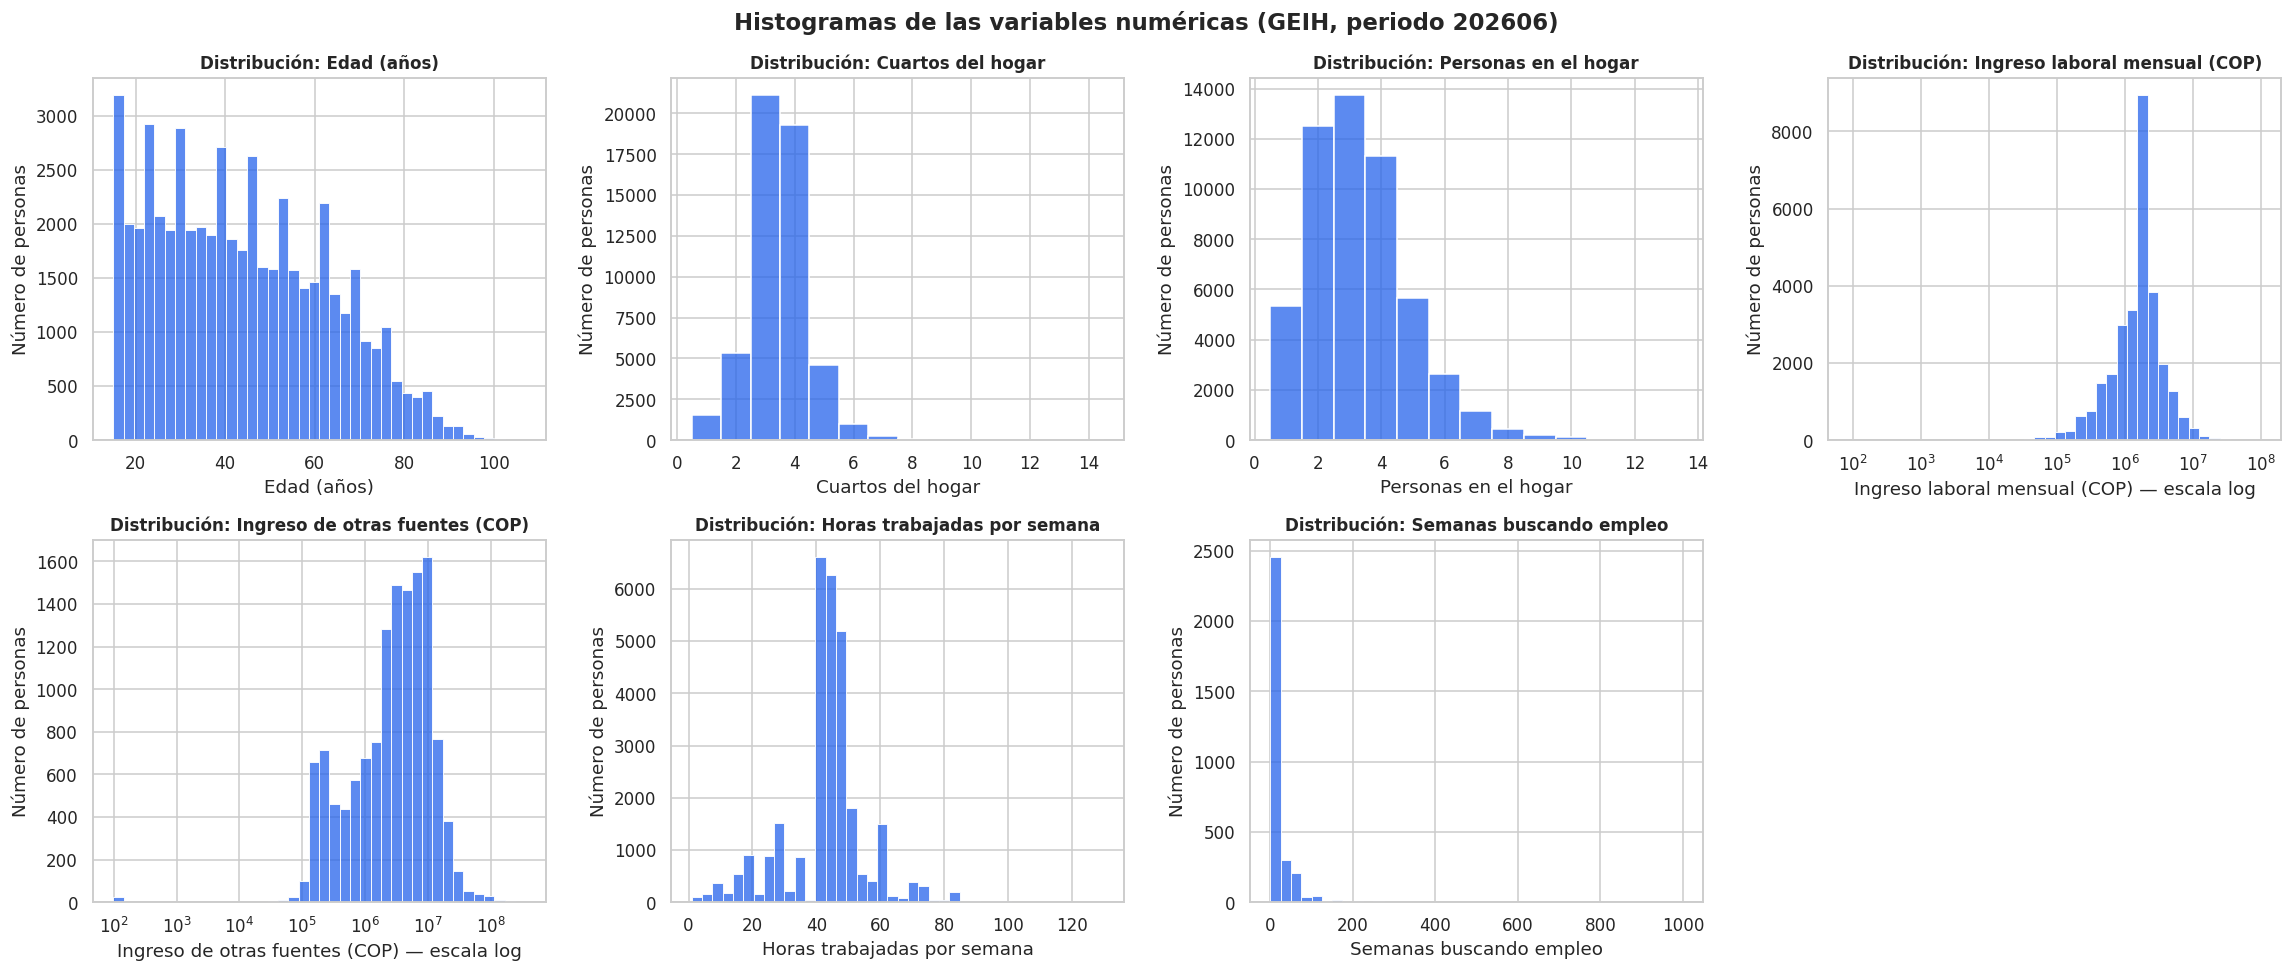

Edad mediana: 42 años
Ingreso laboral: mediana $1,750,905 | media $2,170,873 | p90 $4,000,000
Horas trabajadas: mediana 44 | % que trabaja más de 48 h: 19.0%
Semanas buscando empleo: mediana 10


In [6]:
# GEIH_2026: (columna, usar escala log, variable discreta). Los ingresos son muy asimétricos, por eso van en log.
geih_2026_cfg_hist = [
    ("edad", False, False), ("cuartos", False, True), ("personas_hogar", False, True),
    ("ingreso_laboral", True, False), ("ingreso_otras_fuentes", True, False),
    ("horas_trabajadas", False, False), ("semanas_buscando_trabajo", False, False),
]
fig, axes = plt.subplots(2, 4, figsize=(21, 9))
axes = axes.ravel()

# GEIH_2026: un histograma por variable, usando solo valores con dato (y positivos si es escala log)
for ax, (col, usar_log, discreta) in zip(axes, geih_2026_cfg_hist):
    serie = geih_2026_df[col].dropna()
    if usar_log:
        serie = serie[serie > 0]
    if discreta:
        sns.histplot(serie, discrete=True, color="#2563eb", ax=ax)
    else:
        sns.histplot(serie, bins=40, log_scale=usar_log, color="#2563eb", ax=ax)
    ax.set_title(f"Distribución: {GEIH_2026_ETIQ[col]}", fontsize=11)
    ax.set_xlabel(GEIH_2026_ETIQ[col] + (" — escala log" if usar_log else ""))
    ax.set_ylabel("Número de personas")
axes[-1].axis("off")  # GEIH_2026: 7 variables en una grilla de 8 espacios
fig.suptitle("Histogramas de las variables numéricas (GEIH, periodo 202606)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("geih_2026_histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: cifras clave para redactar el Insight
geih_2026_ing_pos = geih_2026_df.loc[geih_2026_df["ingreso_laboral"] > 0, "ingreso_laboral"]
print(f"Edad mediana: {geih_2026_df['edad'].median():.0f} años")
print(f"Ingreso laboral: mediana ${geih_2026_ing_pos.median():,.0f} | media ${geih_2026_ing_pos.mean():,.0f} | p90 ${geih_2026_ing_pos.quantile(.9):,.0f}")
print(f"Horas trabajadas: mediana {geih_2026_df['horas_trabajadas'].median():.0f} | % que trabaja más de 48 h: {(geih_2026_df['horas_trabajadas'].dropna() > 48).mean()*100:.1f}%")
print(f"Semanas buscando empleo: mediana {geih_2026_df['semanas_buscando_trabajo'].median():.0f}")

**Insight:** La edad mediana de las personas encuestadas es de 42 años, y la mitad de los ocupados con ingreso gana más de $1.750.905 al mes, aunque el 10 % mejor pagado supera los $4.000.000, lo que sube el promedio a $2.170.873. La jornada típica es de 44 horas semanales y el 19 % trabaja más de 48. Quienes buscan empleo llevan una mediana de 10 semanas, cerca de dos meses y medio sin conseguirlo.

## 3. Boxplots y detección de valores atípicos

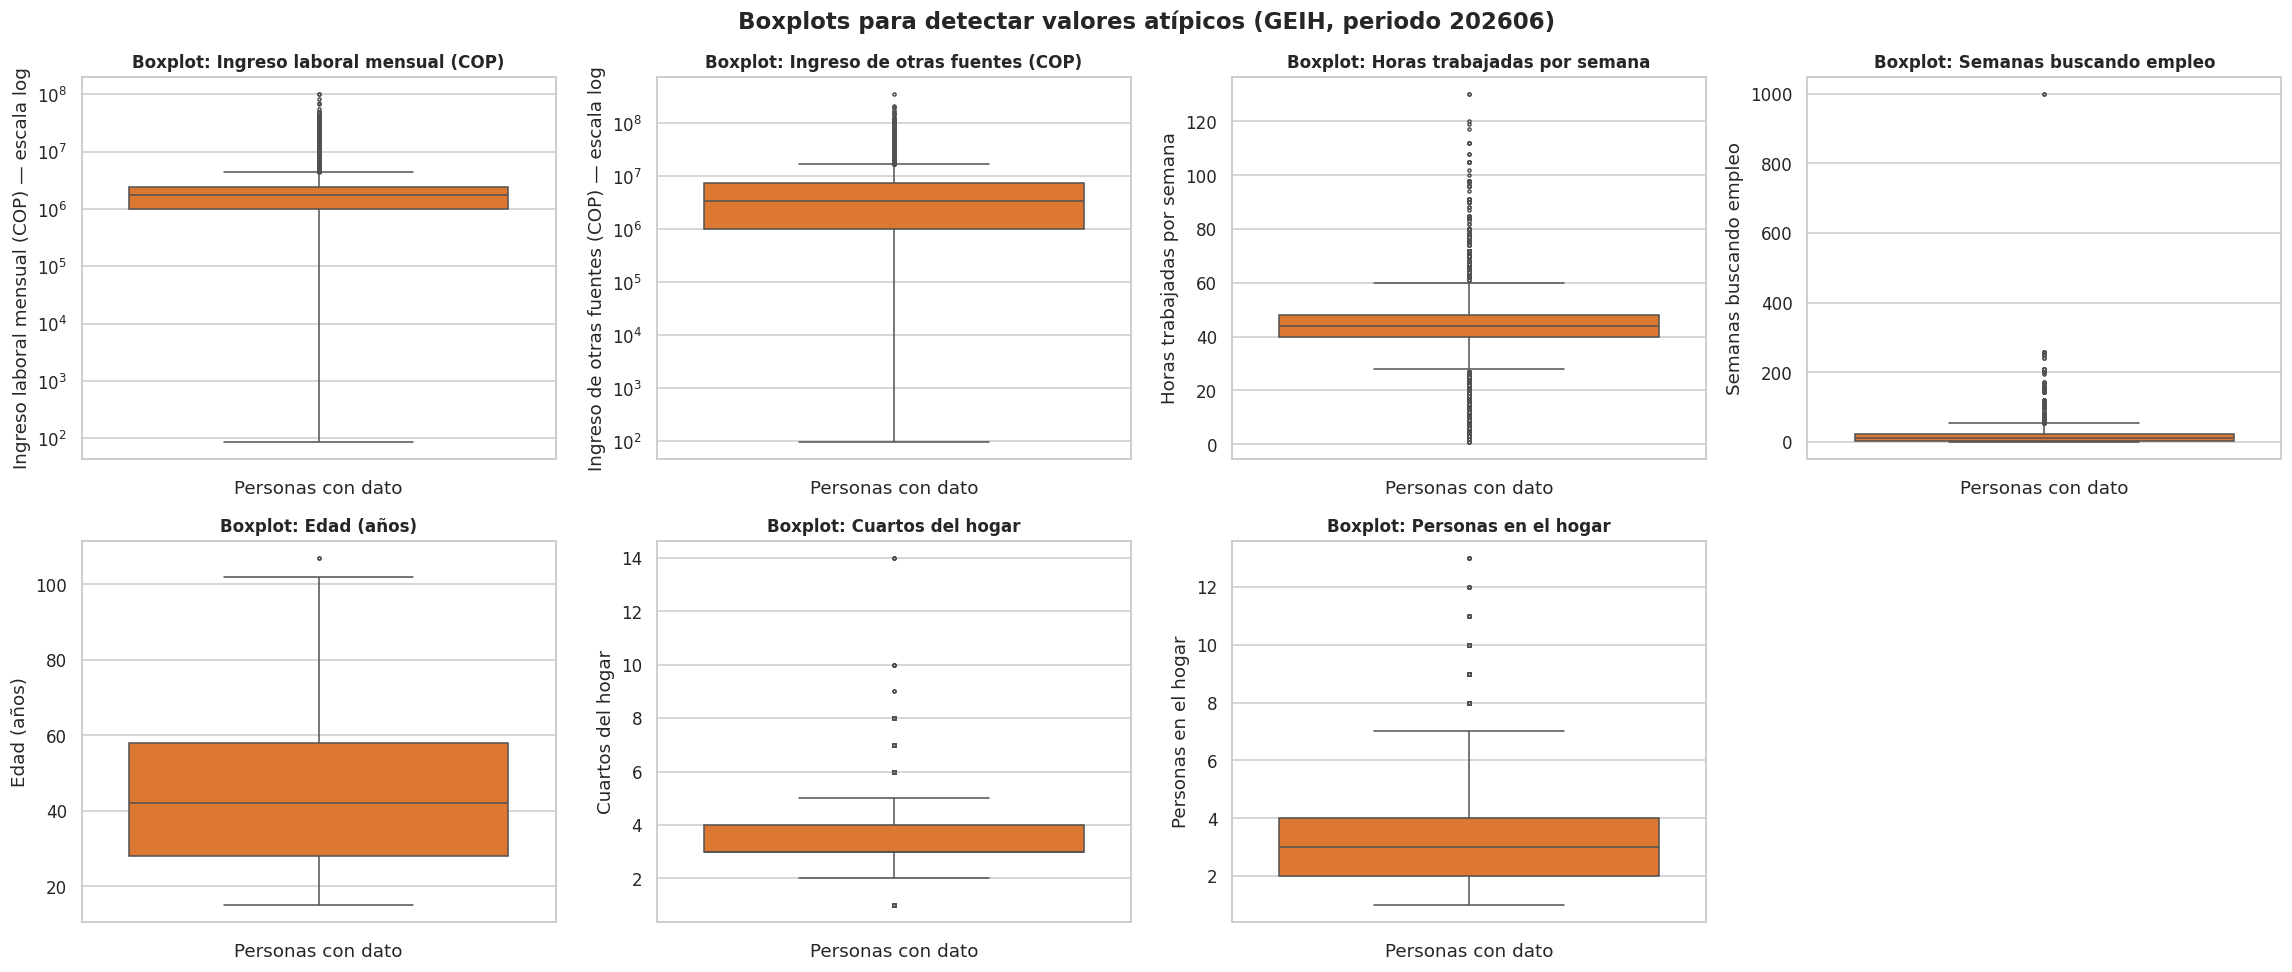

,n,q1,q3,limite_superior,n_atipicos,pct_atipicos
variable,,,,,,
ingreso_laboral,28760,1000000.0,2400000.0,4500000.0,2189,7.6
ingreso_otras_fuentes,13280,1000000.0,7372500.0,16931250.0,670,5.0
horas_trabajadas,29459,40.0,48.0,60.0,4566,15.5
semanas_buscando_trabajo,3092,4.0,24.0,54.0,176,5.7
edad,53131,28.0,58.0,103.0,2,0.0
cuartos,53131,3.0,4.0,5.5,2865,5.4
personas_hogar,53131,2.0,4.0,7.0,854,1.6


In [7]:
def geih_2026_resumen_atipicos(df, columnas, solo_positivos=()):
    """GEIH_2026: cuenta atípicos por la regla del rango intercuartílico (IQR).
    Un valor es atípico si queda por encima de Q3 + 1.5*IQR o por debajo de Q1 - 1.5*IQR.
    Las columnas en `solo_positivos` se evalúan solo con valores > 0 (ingresos)."""
    filas = []
    for col in columnas:
        serie = df[col].dropna()
        if col in solo_positivos:
            serie = serie[serie > 0]
        q1, q3 = serie.quantile(.25), serie.quantile(.75)
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((serie < li) | (serie > ls)).sum())
        filas.append({"variable": col, "n": len(serie), "q1": q1, "q3": q3,
                      "limite_superior": ls, "n_atipicos": n_out, "pct_atipicos": round(n_out / len(serie) * 100, 1)})
    return pd.DataFrame(filas).set_index("variable")

geih_2026_cfg_box = [(c, c in ("ingreso_laboral", "ingreso_otras_fuentes")) for c in geih_2026_num_cols]
fig, axes = plt.subplots(2, 4, figsize=(21, 9))
axes = axes.ravel()

# GEIH_2026: boxplot vertical por variable; ingresos en escala log para que la caja sea legible
for ax, (col, usar_log) in zip(axes, geih_2026_cfg_box):
    serie = geih_2026_df[col].dropna()
    if usar_log:
        serie = serie[serie > 0]
    sns.boxplot(y=serie, color="#f97316", fliersize=2, ax=ax)
    if usar_log:
        ax.set_yscale("log")
    ax.set_title(f"Boxplot: {GEIH_2026_ETIQ[col]}", fontsize=11)
    ax.set_ylabel(GEIH_2026_ETIQ[col] + (" — escala log" if usar_log else ""))
    ax.set_xlabel("Personas con dato")
axes[-1].axis("off")
fig.suptitle("Boxplots para detectar valores atípicos (GEIH, periodo 202606)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("geih_2026_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: tabla de atípicos por IQR (no se eliminan todavía; se decide en la fase de limpieza)
geih_2026_atipicos = geih_2026_resumen_atipicos(
    geih_2026_df, geih_2026_num_cols, solo_positivos=("ingreso_laboral", "ingreso_otras_fuentes"))
geih_2026_atipicos.round(1)

**Insight:** El 7,6 % de los ingresos laborales son atípicos (más de $4.500.000), un grupo pequeño pero real de personas bien pagadas que conviene conservar y no borrar. Las horas trabajadas tienen el mayor porcentaje de atípicos (15,5 %, más de 60 horas semanales) e incluyen registros de hasta 130 horas, que difícilmente son reales y son candidatos a revisión en la limpieza. La edad casi no tiene atípicos (solo 2 casos), así que no requiere tratamiento.

## 4. Correlación entre variables numéricas

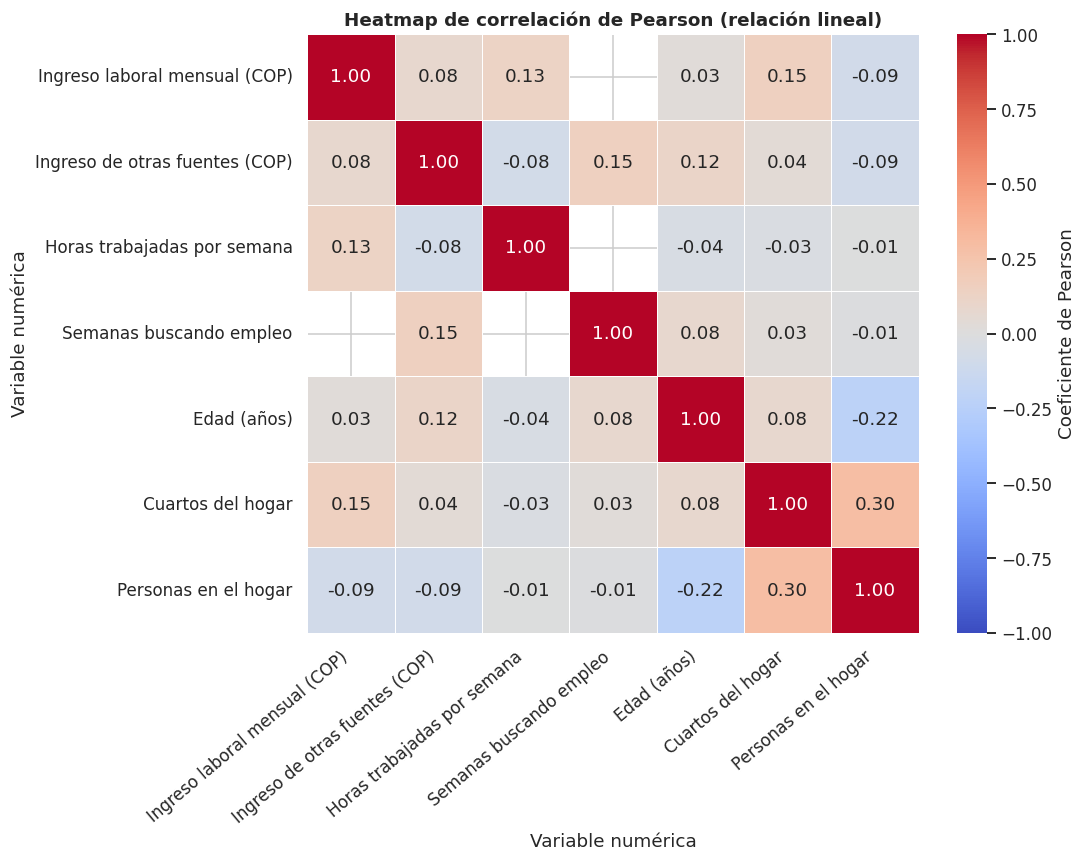

In [8]:
# GEIH_2026: matrices de correlación con etiquetas cortas. pandas usa los pares con dato en ambas variables.
geih_2026_corr_df = geih_2026_df[geih_2026_num_cols].rename(columns=GEIH_2026_ETIQ)
geih_2026_corr_pearson = geih_2026_corr_df.corr(method="pearson")
geih_2026_corr_spearman = geih_2026_corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(geih_2026_corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"label": "Coeficiente de Pearson"}, ax=ax)
ax.set_title("Heatmap de correlación de Pearson (relación lineal)")
ax.set_xlabel("Variable numérica")
ax.set_ylabel("Variable numérica")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("geih_2026_heatmap_pearson.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Ninguna relación lineal es fuerte: la mayor es entre cuartos y personas en el hogar (r = 0,30), coherente con que los hogares más grandes ocupan viviendas más grandes. A mayor edad el hogar tiende a ser más pequeño (r = −0,22), y los ingresos laborales más altos se asocian levemente con viviendas con más cuartos (r = 0,15), una señal del nivel socioeconómico del hogar. Para el negocio, ninguna variable numérica explica por sí sola el ingreso, así que habrá que combinarlas con variables categóricas.

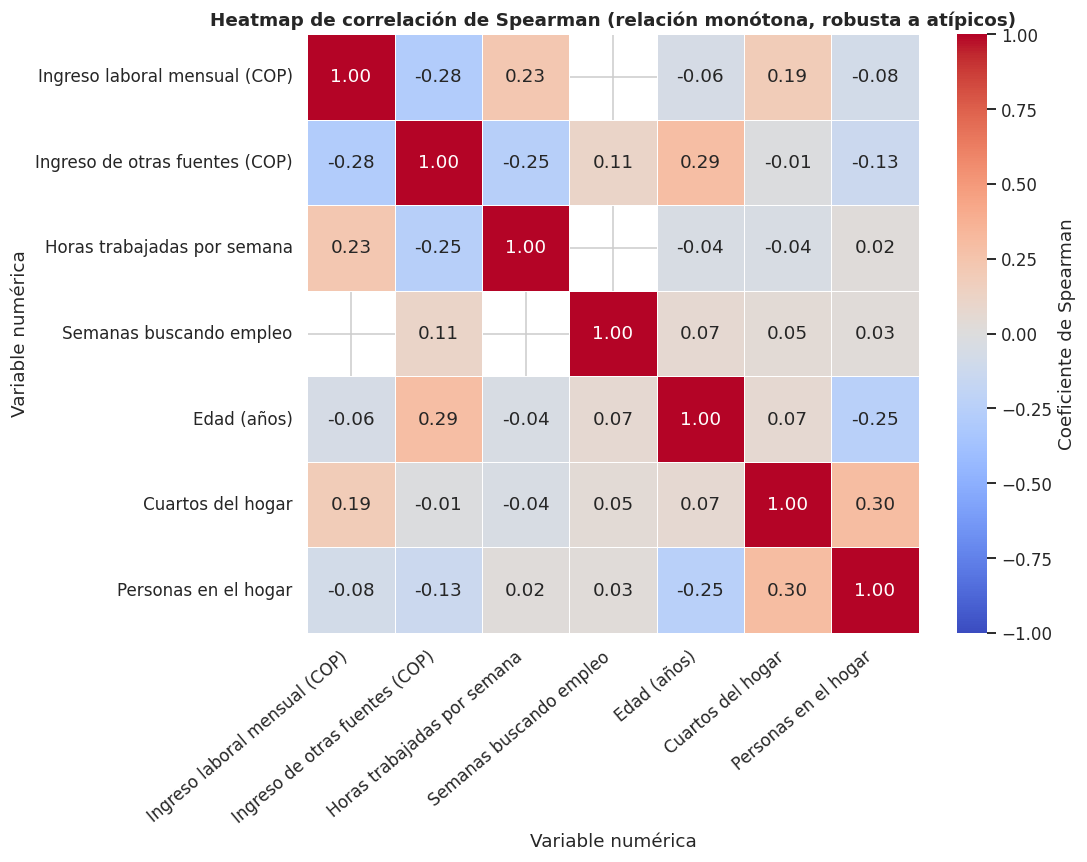

Ingreso de otras fuentes (COP)  Ingreso laboral mensual (COP)     0.37
Edad (años)                     Ingreso de otras fuentes (COP)    0.18
Horas trabajadas por semana     Ingreso de otras fuentes (COP)    0.17
                                Ingreso laboral mensual (COP)     0.10
Edad (años)                     Ingreso laboral mensual (COP)     0.09
dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(geih_2026_corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"label": "Coeficiente de Spearman"}, ax=ax)
ax.set_title("Heatmap de correlación de Spearman (relación monótona, robusta a atípicos)")
ax.set_xlabel("Variable numérica")
ax.set_ylabel("Variable numérica")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("geih_2026_heatmap_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: pares con mayor diferencia entre Spearman y Pearson (señal de no linealidad o atípicos)
geih_2026_dif = (geih_2026_corr_spearman - geih_2026_corr_pearson).abs().stack()
geih_2026_dif = geih_2026_dif[geih_2026_dif.index.get_level_values(0) < geih_2026_dif.index.get_level_values(1)]
print(geih_2026_dif.sort_values(ascending=False).head(5).round(2))

**Insight:** Spearman confirma la relación entre cuartos y personas (0,30) y muestra dos asociaciones que Pearson casi no refleja: el ingreso de otras fuentes crece con la edad (0,29) y se mueve en sentido contrario al ingreso laboral (−0,28). Esto sugiere que las personas mayores dependen más de ingresos distintos al trabajo y que estos compensan parcialmente a quienes ganan menos por trabajar. Al ser relaciones monótonas pero no lineales, en el modelado conviene transformar los ingresos (por ejemplo, con logaritmo).

## 5. Gráficos adicionales con insight de negocio

### 5.1 Barras: estado ocupacional según sexo

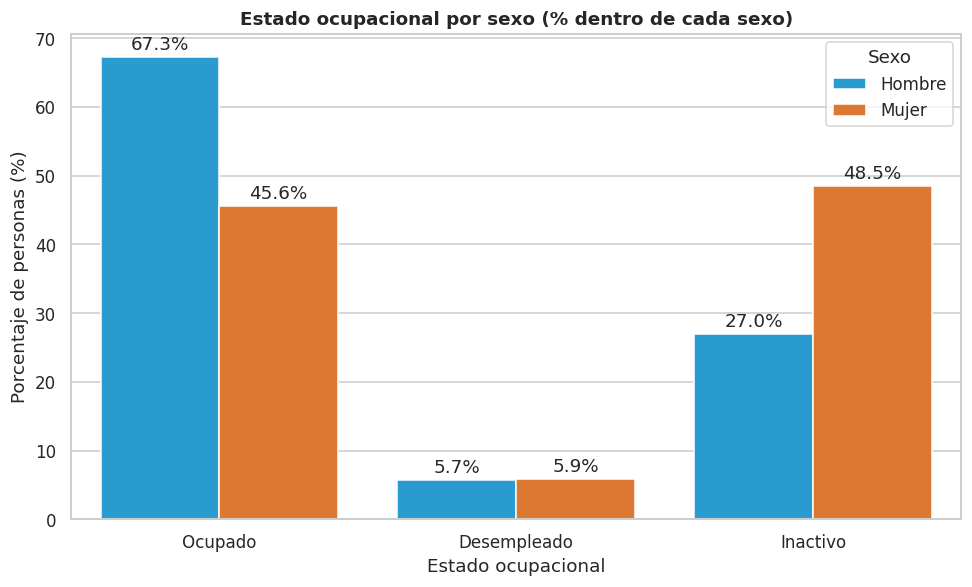

In [10]:
# GEIH_2026: porcentaje de cada sexo en cada estado ocupacional (se compara dentro de cada sexo)
geih_2026_df_estado = (geih_2026_df.dropna(subset=["sexo"])
                            .groupby("sexo")["estado_ocupacional"].value_counts(normalize=True)
                            .mul(100).rename("porcentaje").reset_index())
geih_2026_orden_estado = [e for e in ["Ocupado", "Desempleado", "Inactivo", "Sin clasificar"]
                               if e in geih_2026_df_estado["estado_ocupacional"].unique()]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=geih_2026_df_estado, x="estado_ocupacional", y="porcentaje", hue="sexo",
            order=geih_2026_orden_estado, palette={"Hombre": "#0ea5e9", "Mujer": "#f97316"}, ax=ax)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=2)
ax.set_title("Estado ocupacional por sexo (% dentro de cada sexo)")
ax.set_xlabel("Estado ocupacional")
ax.set_ylabel("Porcentaje de personas (%)")
ax.legend(title="Sexo")
plt.tight_layout()
plt.savefig("geih_2026_barras_estado_sexo.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** La brecha entre sexos está en la participación y no en el desempleo: el 67,3 % de los hombres está ocupado frente al 45,6 % de las mujeres, mientras que el desempleo es casi igual (5,7 % y 5,9 %). La diferencia se explica porque el 48,5 % de las mujeres está inactiva frente al 27,0 % de los hombres, 21,5 puntos más. Esto apunta a barreras de entrada al mercado laboral, como el trabajo de cuidado no remunerado (hipótesis por verificar con otras variables de la encuesta), y el sexo debe usarse con cuidado ético en los modelos.

### 5.2 Violin: ingreso laboral según nivel educativo

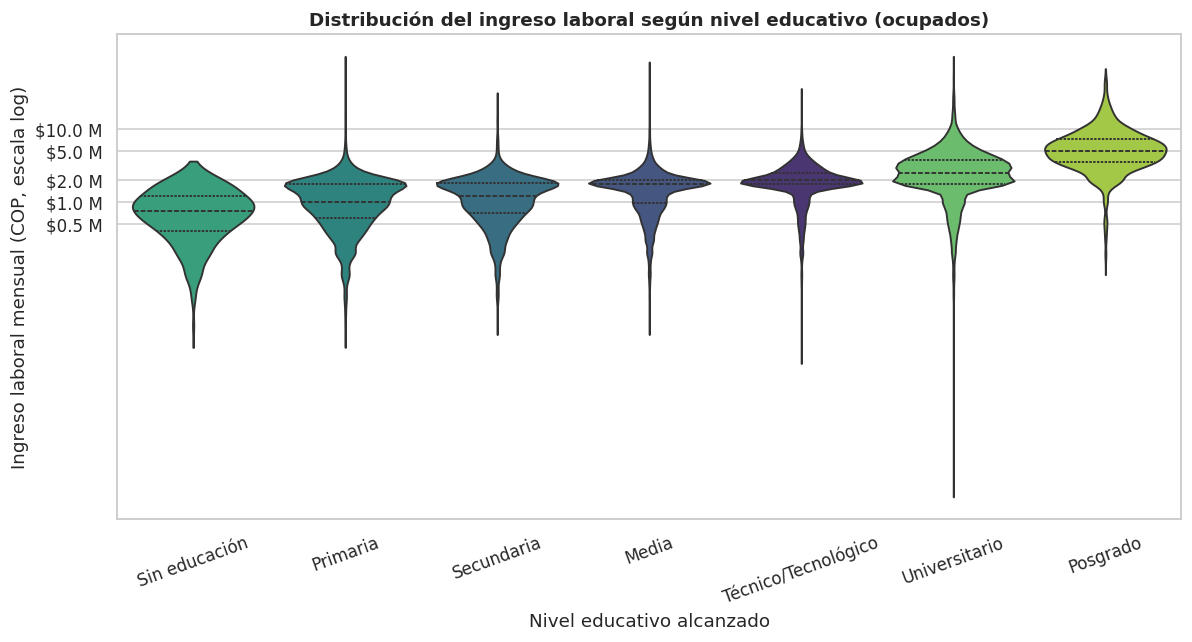

nivel_educativo_grupo
Sin educación           747000.0
Primaria               1000000.0
Secundaria             1200000.0
Media                  1750000.0
Técnico/Tecnológico    2000000.0
Universitario          2500000.0
Posgrado               5000000.0
Name: ingreso_laboral, dtype: float64


In [11]:
# GEIH_2026: solo ocupados con ingreso positivo; se usa log10 porque el ingreso es muy asimétrico
geih_2026_df_ocup = geih_2026_df[(geih_2026_df["estado_ocupacional"] == "Ocupado")
                                           & (geih_2026_df["ingreso_laboral"] > 0)
                                           & geih_2026_df["nivel_educativo_grupo"].notna()].copy()
geih_2026_df_ocup["log10_ingreso"] = np.log10(geih_2026_df_ocup["ingreso_laboral"])
geih_2026_orden_edu = [n for n in GEIH_2026_ORDEN_EDU if n in geih_2026_df_ocup["nivel_educativo_grupo"].unique()]

fig, ax = plt.subplots(figsize=(11, 6))
sns.violinplot(data=geih_2026_df_ocup, x="nivel_educativo_grupo", y="log10_ingreso", order=geih_2026_orden_edu,
               hue="nivel_educativo_grupo", palette="viridis", legend=False, cut=0, inner="quartile", ax=ax)
geih_2026_ticks = [5e5, 1e6, 2e6, 5e6, 1e7]
ax.set_yticks(np.log10(geih_2026_ticks))
ax.set_yticklabels([f"${t/1e6:.1f} M" for t in geih_2026_ticks])
ax.set_title("Distribución del ingreso laboral según nivel educativo (ocupados)")
ax.set_xlabel("Nivel educativo alcanzado")
ax.set_ylabel("Ingreso laboral mensual (COP, escala log)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("geih_2026_violin_ingreso_educacion.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: mediana de ingreso por nivel para citar en el Insight
print(geih_2026_df_ocup.groupby("nivel_educativo_grupo")["ingreso_laboral"].median().reindex(geih_2026_orden_edu).round(0))

**Insight:** El ingreso sube escalonadamente con la educación: la mediana pasa de $747.000 sin educación a $2.500.000 con título universitario y a $5.000.000 con posgrado, es decir, 6,7 veces más. El salto más grande ocurre entre universitario y posgrado, donde la mediana se duplica. Por eso el nivel educativo es la variable candidata nº 1 para predecir ingreso en el modelado supervisado.

### 5.3 Barras horizontales: departamentos con mayor tasa de desempleo

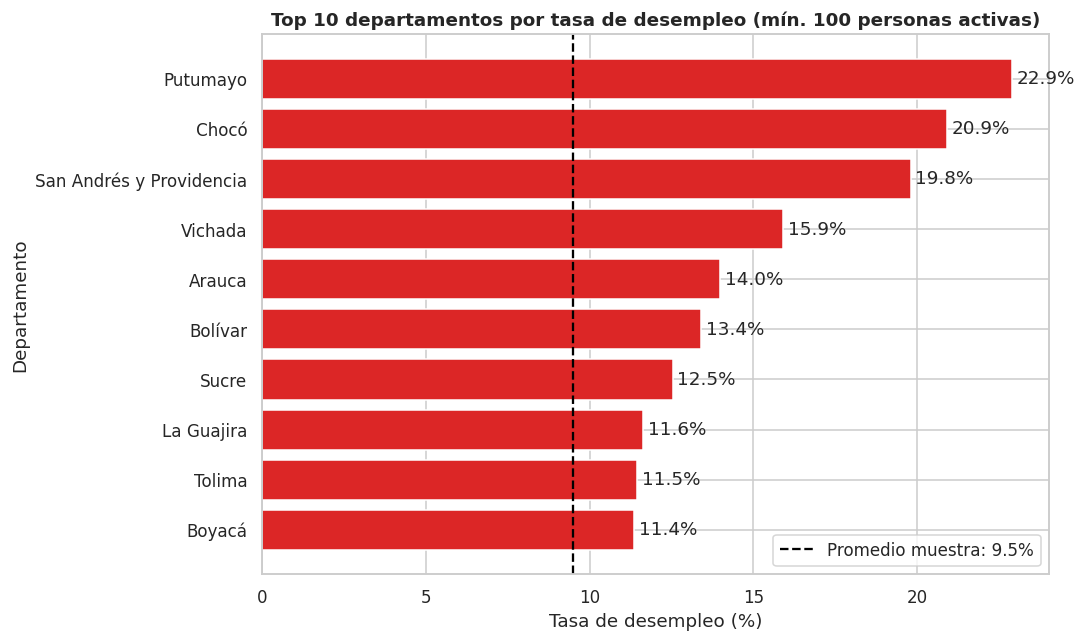

In [12]:
# GEIH_2026: tasa de desempleo = desempleados / (ocupados + desempleados), solo en departamentos con muestra suficiente
geih_2026_pea = geih_2026_df[geih_2026_df["estado_ocupacional"].isin(["Ocupado", "Desempleado"])
                                       & geih_2026_df["departamento"].notna()]
geih_2026_df_depto = (geih_2026_pea.groupby("departamento")
                           .agg(pea=("id_hecho", "size"),
                                desempleados=("estado_ocupacional", lambda s: (s == "Desempleado").sum())))
geih_2026_df_depto["tasa_desempleo"] = geih_2026_df_depto["desempleados"] / geih_2026_df_depto["pea"] * 100
geih_2026_df_top = (geih_2026_df_depto[geih_2026_df_depto["pea"] >= 100]
                         .sort_values("tasa_desempleo", ascending=False).head(10).iloc[::-1])

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(geih_2026_df_top.index, geih_2026_df_top["tasa_desempleo"], color="#dc2626")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
tasa_nacional = (geih_2026_pea["estado_ocupacional"] == "Desempleado").mean() * 100
ax.axvline(tasa_nacional, color="black", linestyle="--", label=f"Promedio muestra: {tasa_nacional:.1f}%")
ax.set_title("Top 10 departamentos por tasa de desempleo (mín. 100 personas activas)")
ax.set_xlabel("Tasa de desempleo (%)")
ax.set_ylabel("Departamento")
ax.legend()
plt.tight_layout()
plt.savefig("geih_2026_barras_desempleo_departamento.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Chocó (20,9 %) y San Andrés y Providencia (19,8 %) tienen las mayores tasas de desempleo con muestras suficientes, más del doble del promedio de la muestra (9,5 %); Putumayo (22,9 %) encabeza la lista, pero con solo 153 personas activas su cifra es menos estable. Bolívar (13,4 %) y Sucre (12,5 %) también superan el promedio con más de 1.300 personas activas cada uno. El lugar de residencia condiciona las oportunidades laborales y justifica incluir el departamento en los modelos.

### 5.4 Scatter: edad vs. ingreso laboral

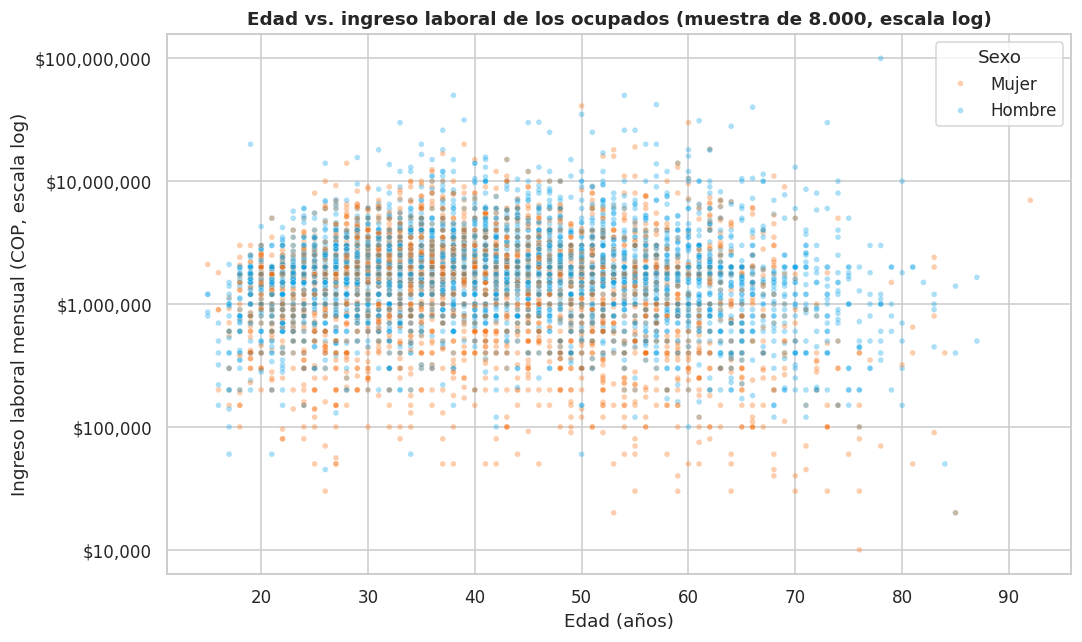

sexo           Hombre      Mujer
grupo_edad                      
<25         1600000.0  1500000.0
25-34       1800000.0  1750905.0
35-44       2000000.0  1750905.0
45-54       1800000.0  1750000.0
55-64       1750000.0  1122274.0
65+         1000000.0   600000.0


In [13]:
# GEIH_2026: muestra aleatoria reproducible para que el scatter sea legible y rápido
geih_2026_muestra = geih_2026_df_ocup.dropna(subset=["sexo"]).sample(
    n=min(8000, len(geih_2026_df_ocup)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=geih_2026_muestra, x="edad", y="ingreso_laboral", hue="sexo", alpha=.35, s=14,
                palette={"Hombre": "#0ea5e9", "Mujer": "#f97316"}, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(GEIH_2026_COP)
ax.set_title("Edad vs. ingreso laboral de los ocupados (muestra de 8.000, escala log)")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Ingreso laboral mensual (COP, escala log)")
ax.legend(title="Sexo")
plt.tight_layout()
plt.savefig("geih_2026_scatter_edad_ingreso.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: mediana de ingreso por grupo de edad y sexo para respaldar el Insight
geih_2026_df_ocup["grupo_edad"] = pd.cut(geih_2026_df_ocup["edad"], [0, 24, 34, 44, 54, 64, 120],
                                              labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])
print(geih_2026_df_ocup.pivot_table(index="grupo_edad", columns="sexo", values="ingreso_laboral",
                                         aggfunc="median", observed=True).round(0))

**Insight:** El ingreso de los hombres alcanza su punto más alto entre los 35 y 44 años (mediana de $2.000.000) y cae a $1.000.000 después de los 65, mientras que el de las mujeres se mantiene cerca de $1.750.000 entre los 25 y 54 años y baja a $1.122.274 a los 55-64 y a $600.000 después de los 65. La brecha se amplía con la edad: ellas ganan el 88 % de lo que ganan ellos a los 35-44 años, el 64 % a los 55-64 y el 60 % después de los 65. La edad por sí sola explica poco del ingreso, pues el 10 % mejor pagado supera los $4.000.000 frente a una mediana de $1.750.905.

## 6. Resumen de hallazgos

In [14]:
# GEIH_2026: tabla de cifras clave para redactar el documento de 1-2 páginas
geih_2026_ing = geih_2026_df_ocup["ingreso_laboral"]
geih_2026_med_sexo = geih_2026_df_ocup.groupby("sexo")["ingreso_laboral"].median()
geih_2026_med_edu = geih_2026_df_ocup.groupby("nivel_educativo_grupo")["ingreso_laboral"].median()
geih_2026_estado = geih_2026_df["estado_ocupacional"].value_counts(normalize=True).mul(100)

geih_2026_df_resumen = pd.Series({
    "Personas en el dataset": f"{len(geih_2026_df):,}",
    "% Ocupados": f"{geih_2026_estado.get('Ocupado', np.nan):.1f}%",
    "% Desempleados": f"{geih_2026_estado.get('Desempleado', np.nan):.1f}%",
    "% Inactivos": f"{geih_2026_estado.get('Inactivo', np.nan):.1f}%",
    "Mediana ingreso laboral (COP)": f"${geih_2026_ing.median():,.0f}",
    "Media / mediana de ingreso": f"{geih_2026_ing.mean() / geih_2026_ing.median():.2f}x",
    "Mediana ingreso mujeres / hombres": f"{geih_2026_med_sexo.get('Mujer', np.nan) / geih_2026_med_sexo.get('Hombre', np.nan):.2f}",
    "Mediana posgrado / sin educación": f"{geih_2026_med_edu.get('Posgrado', np.nan) / geih_2026_med_edu.get('Sin educación', np.nan):.1f}x",
    "% atípicos ingreso laboral (IQR)": f"{geih_2026_atipicos.loc['ingreso_laboral', 'pct_atipicos']}%",
}, name="valor").to_frame()
geih_2026_df_resumen

,valor
Personas en el dataset,"53,131"
% Ocupados,55.4%
% Desempleados,5.8%
% Inactivos,38.7%
Mediana ingreso laboral (COP),"$1,750,905"
Media / mediana de ingreso,1.24x
Mediana ingreso mujeres / hombres,1.00
Mediana posgrado / sin educación,6.7x
% atípicos ingreso laboral (IQR),7.6%


### Los 3 hallazgos más importantes

1. **El ingreso depende fuertemente de la educación.** La mediana de quien tiene posgrado ($5.000.000) es 6,7 veces la de quien no tiene educación formal ($747.000) → el nivel educativo es la variable candidata nº 1 para predecir ingreso.
2. **La brecha entre mujeres y hombres está en la participación y crece con la edad.** El 67,3 % de los hombres está ocupado frente al 45,6 % de las mujeres, y entre las ocupadas de 55 años o más su ingreso mediano es 60-64 % del de los hombres → el sexo debe analizarse con cuidado ético al modelar.
3. **La mitad de los ocupados gana el salario mínimo o menos.** La mediana ($1.750.905) coincide con el salario mínimo de 2026, y el 7,6 % de los ingresos son atípicos por IQR (más de $4.500.000) → en la limpieza hay que conservar los atípicos reales y aplicar transformación logarítmica antes de modelar.

**Siguiente fase:** limpieza y normalización (códigos 98/99, nulos estructurales vs. reales, tratamiento de atípicos, escalado y codificación de categóricas) y modelos supervisados y no supervisados.

In [15]:
import glob, shutil
os_destino = "/content/drive/MyDrive/GEIH/figuras"
import os; os.makedirs(os_destino, exist_ok=True)
for f in glob.glob("geih_2026_*.png"):
    shutil.copy(f, os_destino)